# Lab 2, step by step

**The story of this lab:**
1. We are given a network called `BrokenNet` that does not learn.
2. We look inside it to find out *why*.
3. We try fixes **one at a time** and see which one works.

Each step below has a short explanation, then a small piece of code. Run the cells **in order** with **Shift+Enter** and read the printout after each one.

This notebook must be in the same folder as `lab02_starter.py`.

## Step 1: Import the tools

- `torch`: PyTorch, the deep learning library.
- `torch.nn`: the building blocks of networks (layers).
- `torch.nn.functional` (called `F`): ready-made functions, like the loss function.
- `matplotlib.pyplot`: for drawing graphs.
- From `lab02_starter.py` we import the broken network and the function that makes the data.

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

from lab02_starter import BrokenNet, make_toy_classification

print("Imports worked")

Imports worked


## Step 2: Get the data and look at it

`make_toy_classification` makes a small fake dataset:
- `x`: 256 examples, each one is a list of 20 numbers.
- `y`: the answer for each example, either 0 or 1.

The network's job is to look at the 20 numbers and guess 0 or 1.

In [2]:
x, y = make_toy_classification(seed=0)

print("x shape:", x.shape)          # 256 rows, 20 numbers each
print("y shape:", y.shape)          # 256 answers
print("First example:", x[0])
print("Its answer:", y[0].item())
print("How many 1s:", int(y.sum().item()), "out of", len(y))

x shape: torch.Size([256, 20])
y shape: torch.Size([256])
First example: tensor([-1.1258, -1.1524, -0.2506, -0.4339,  0.8487,  0.6920, -0.3160, -2.1152,
         0.3223, -1.2633,  0.3500,  0.3081,  0.1198,  1.2377,  1.1168, -0.2473,
        -1.3527, -1.6959,  0.5667,  0.7935])
Its answer: 0.0
How many 1s: 141 out of 256


## Step 3: Build the broken network and look at it

`BrokenNet` has:
- **8 hidden layers**, each with 32 units (the first one takes the 20 input numbers);
- a **ReLU** after each hidden layer. ReLU keeps positive numbers and turns every negative number into 0;
- **1 output layer** that gives one score: above 0 means "guess 1", below 0 means "guess 0".

`torch.manual_seed(0)` makes the random starting weights the same every time we run this.

In [3]:
torch.manual_seed(0)
model = BrokenNet()
print(model)

BrokenNet(
  (hidden): ModuleList(
    (0): Linear(in_features=20, out_features=32, bias=True)
    (1-7): 7 x Linear(in_features=32, out_features=32, bias=True)
  )
  (out): Linear(in_features=32, out_features=1, bias=True)
)


## Step 4: Train it and watch it fail

This is the same training loop as in Lab 1:
1. `zero_grad()`: clear the old gradients;
2. forward: get the network's guesses;
3. loss: measure how wrong the guesses are;
4. `backward()`: work out how to change each weight;
5. `step()`: change the weights a little.

**What to look for:** a model that has learned nothing scores a loss of about **0.693** on this task. If the loss stays near 0.693, the network is not learning.

In [4]:
optimizer = torch.optim.SGD(model.parameters(), lr=0.1)

for epoch in range(50):
    optimizer.zero_grad()                                   # 1. clear old gradients
    guesses = model(x).squeeze(-1)                          # 2. forward pass (squeeze turns 256x1 into 256)
    loss = F.binary_cross_entropy_with_logits(guesses, y)   # 3. how wrong are we?
    loss.backward()                                         # 4. compute gradients
    optimizer.step()                                        # 5. update weights

    if epoch % 10 == 0 or epoch == 49:
        print(f"epoch {epoch:2d}: loss = {loss.item():.4f}")

epoch  0: loss = 0.7037
epoch 10: loss = 0.6974
epoch 20: loss = 0.6937
epoch 30: loss = 0.6914
epoch 40: loss = 0.6901
epoch 49: loss = 0.6893


**What I see:** The loss only moves from 0.704 to 0.689, basicaly learned nothing.

---

## Step 5: Look inside. Do the layers pass anything forward?

We push the data through the layers **one at a time** and count, at each layer, what fraction of numbers come out **above 0**. Remember: ReLU turns every negative number into 0. If almost everything is 0, the layer is "dead": nothing passes through it.

In [5]:
torch.manual_seed(0)
model = BrokenNet()                       # a fresh, untrained broken network

h = x                                     # start with the input data
for i, layer in enumerate(model.hidden):
    before_relu = layer(h)                # the layer's output before ReLU
    h = torch.relu(before_relu)           # after ReLU (negatives become 0)
    above_zero = (before_relu > 0).float().mean().item()
    print(f"layer {i + 1}: {above_zero:.0%} of values are above 0")

layer 1: 7% of values are above 0
layer 2: 0% of values are above 0
layer 3: 0% of values are above 0
layer 4: 0% of values are above 0
layer 5: 0% of values are above 0
layer 6: 0% of values are above 0
layer 7: 0% of values are above 0
layer 8: 0% of values are above 0


**What I see:** Only 7% of values pass layer 1, and 0% pass layers 2 to 8, so the network is dead from layer 2 on.

---

## Step 6: Check the gradients. Does any learning signal reach the layers?

The **gradient** of a layer says how its weights should change. If the gradient is **exactly 0**, that layer cannot learn at all.

We do one forward and one backward pass, then print the average size of the gradient for each layer.

In [6]:
torch.manual_seed(0)
model = BrokenNet()

guesses = model(x).squeeze(-1)
loss = F.binary_cross_entropy_with_logits(guesses, y)
loss.backward()                           # fill in every layer's gradient

for i, layer in enumerate(model.hidden):
    grad_size = layer.weight.grad.abs().mean().item()
    print(f"layer {i + 1}: average gradient size = {grad_size:.2e}")

layer 1: average gradient size = 0.00e+00
layer 2: average gradient size = 0.00e+00
layer 3: average gradient size = 0.00e+00
layer 4: average gradient size = 0.00e+00
layer 5: average gradient size = 0.00e+00
layer 6: average gradient size = 0.00e+00
layer 7: average gradient size = 0.00e+00
layer 8: average gradient size = 0.00e+00


**What I see:** The gradient is exactly 0 in all 8 hidden layers, so none of them can learn.

---

## Step 7: Why? Look at how BrokenNet sets its starting weights

Open `lab02_starter.py`. In `BrokenNet` there are these two lines:

```python
nn.init.normal_(layer.weight, mean=0.0, std=0.3)
nn.init.constant_(layer.bias, -2.0)
```

- Every layer adds a **bias of -2** to its output, so almost every value starts out **negative**.
- ReLU turns negative values into **0**, so the layer passes nothing forward.
- A ReLU that outputs 0 also passes back a gradient of **0**, so the layer can never learn its way out.

This is called **dying ReLU**. The cell below shows the biases really are -2.

In [7]:
torch.manual_seed(0)
model = BrokenNet()
print("Biases of layer 1 (first 5):", model.hidden[0].bias[:5])

Biases of layer 1 (first 5): tensor([-2., -2., -2., -2., -2.], grad_fn=<SliceBackward0>)


---

# Now we fix it, one change at a time

To compare fairly, every fix uses the **same training function**. Only one thing changes each time.

## Step 8: A training function we can reuse

Same loop as Step 4, wrapped in a function so we can call it for each fix. It returns the list of losses, one per epoch.

In [8]:
def train(model, optimizer, epochs=50):
    losses = []
    for epoch in range(epochs):
        optimizer.zero_grad()
        loss = F.binary_cross_entropy_with_logits(model(x).squeeze(-1), y)
        loss.backward()
        optimizer.step()
        losses.append(loss.item())
    return losses

# Stage 0: the broken network, as given (our baseline)
torch.manual_seed(0)
model = BrokenNet()
losses_baseline = train(model, torch.optim.SGD(model.parameters(), lr=0.1))
print("Stage 0 (baseline) final loss:", round(losses_baseline[-1], 4))

Stage 0 (baseline) final loss: 0.6893


## Step 9: Fix 1, change only the starting weights (initialization)

We replace BrokenNet's bad starting values with good ones:
- **Kaiming** initialization for the weights: a standard choice for ReLU networks that keeps values at a healthy size from layer to layer;
- biases set to **0** instead of -2.

Everything else (layers, ReLU, SGD, learning rate, epochs) stays the same.

In [9]:
torch.manual_seed(0)
model = BrokenNet()

for layer in model.hidden:
    nn.init.kaiming_normal_(layer.weight, nonlinearity="relu")   # good starting weights
    nn.init.zeros_(layer.bias)                                    # bias 0 instead of -2

losses_init = train(model, torch.optim.SGD(model.parameters(), lr=0.1))
print("Stage 1 (init fix) final loss:", round(losses_init[-1], 4))

Stage 1 (init fix) final loss: 0.3632


## Step 10: Fix 2, add BatchNorm only (keep the bad starting weights)

**BatchNorm** re-centres each layer's values around 0 before the ReLU, every time. So even with the -2 bias, about half the values end up above 0 again.

To add it we need a slightly changed copy of BrokenNet. `class BrokenNetWithBatchNorm(BrokenNet)` means "everything from BrokenNet, plus what we add here":
- in `__init__`, we create one BatchNorm per hidden layer;
- in `forward`, we put the BatchNorm between each layer and its ReLU.

In [10]:
class BrokenNetWithBatchNorm(BrokenNet):
    def __init__(self):
        super().__init__()                                         # build BrokenNet exactly as before
        self.norms = nn.ModuleList([nn.BatchNorm1d(32) for _ in range(8)])

    def forward(self, x):
        for layer, norm in zip(self.hidden, self.norms):
            x = torch.relu(norm(layer(x)))                         # layer -> BatchNorm -> ReLU
        return self.out(x)


torch.manual_seed(0)
model = BrokenNetWithBatchNorm()
losses_norm = train(model, torch.optim.SGD(model.parameters(), lr=0.1))
print("Stage 2 (BatchNorm) final loss:", round(losses_norm[-1], 4))

Stage 2 (BatchNorm) final loss: 0.2437


## Step 11: Fix 3, change only the optimizer

We keep BrokenNet exactly as it is, and only swap SGD for **AdamW**, a smarter optimizer.

**Prediction:** if the gradients are exactly 0, no optimizer can help, because every optimizer builds its update from the gradient. Let's check.

In [11]:
torch.manual_seed(0)
model = BrokenNet()
losses_adamw = train(model, torch.optim.AdamW(model.parameters(), lr=1e-3))
print("Stage 3 (AdamW only) final loss:", round(losses_adamw[-1], 4))

Stage 3 (AdamW only) final loss: 0.6997


## Step 12: Compare everything in one graph

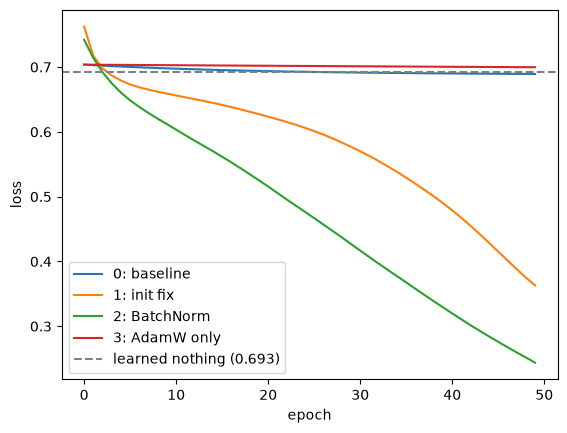

<Figure size 640x480 with 0 Axes>

In [13]:
plt.plot(losses_baseline, label="0: baseline")
plt.plot(losses_init, label="1: init fix")
plt.plot(losses_norm, label="2: BatchNorm")
plt.plot(losses_adamw, label="3: AdamW only")
plt.axhline(0.693, color="grey", linestyle="--", label="learned nothing (0.693)")
plt.xlabel("epoch")
plt.ylabel("loss")
plt.legend()
plt.show()

plt.savefig("stage_comparison.png", dpi=150, bbox_inches="tight")

## Step 13: My conclusion

The grey dashed line at 0.693 is “learned nothing.” On this task, a network that just guesses 50/50 every time scores exactly 0.693. Any line that stays on it has learned nothing.

Reading the graph:

| Line | What it does | Meaning |
|---|---|---|
| 🔵 0: baseline (BrokenNet) | Flat, right on 0.693 (final 0.6893) | Not learning at all. This is the problem we diagnosed |
| 🔴 3: AdamW only | Flat, right on 0.693 (final 0.6997) | Not learning either. A better optimizer didn't help |
| 🟠 1: init fix | Goes down to 0.3632 | Learning. Fixing the starting weights brought it to life |
| 🟢 2: BatchNorm | Goes down fastest, to 0.2437 | Learning best. The lowest loss, so the most-right guesses |

The orange and green lines are both still going down at epoch 50, so they would keep improving with more epochs.


**What was wrong?** The −2 bias made almost every value negative, so ReLU output 0 and the layers were dead: no values got through and the gradient was 0 (Steps 5–7). That’s why the blue line is flat at 0.693.

**Diagnosis:** BrokenNet suffers from dying ReLU. The bias of −2 pushes almost every value below zero, so ReLU outputs 0: only 7% of values pass layer 1 and none pass layers 2–8 (Step 5). A ReLU that outputs 0 also passes back a gradient of 0, so every hidden layer receives exactly zero gradient (Step 6). The only thing that can still learn is the output layer’s bias, which is why the loss creeps down slightly (0.704 → 0.689): the network just learns to guess the more common class.

**Which change mattered most:** BatchNorm gave the lowest loss (0.2437), ahead of the initialization fix (0.3632). BatchNorm re-centres each layer’s values around zero before the ReLU on every batch, which cancels the −2 shift even though the bad initialization is still there. The init fix removes the cause instead, but SGD then has to start from scratch, so it learns more slowly in 50 epochs.

**Why the optimizer alone did not help:** every optimizer builds its update from the gradient. With an exactly-zero gradient, AdamW has nothing to work with, so the loss stayed at 0.6997. It ended slightly above the baseline because AdamW’s smaller learning rate (0.001) moves the output bias more slowly than SGD’s 0.1.